In [2]:
!pip install gymnasium gym_bandits


In [16]:
import gym
import gym_bandits
import numpy as np


In [17]:
env=gym.make('MultiarmedBandits-v0')

In [18]:
print(env.observation_space)

Discrete(1)


In [19]:
print(env.action_space)

Discrete(10)


In [20]:
n_arms =env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards =[]
action_history = []



In [22]:
for episode in range(num_episodes):
    env.reset()

    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(q_values)

    observation, reward, done, info = env.step(action)

    counts[action] += 1
    reward_sums[action] += reward
    q_values[action] = reward_sums[action] / counts[action]

    all_rewards.append(reward)
    action_history.append(action)


env.close()

print("Estimated q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was selected:", counts.astype(int))
print("Average reward over all episodes:", round(np.mean(all_rewards), 2))

Estimated q-values for each arm: [-0.24 -0.31  0.39  0.05 -0.47  0.03  0.01  0.09  0.04 -1.1 ]
Number of times each arm was selected: [  9  11  28  20   7   7  78 327  10   3]
Average reward over all episodes: 0.06


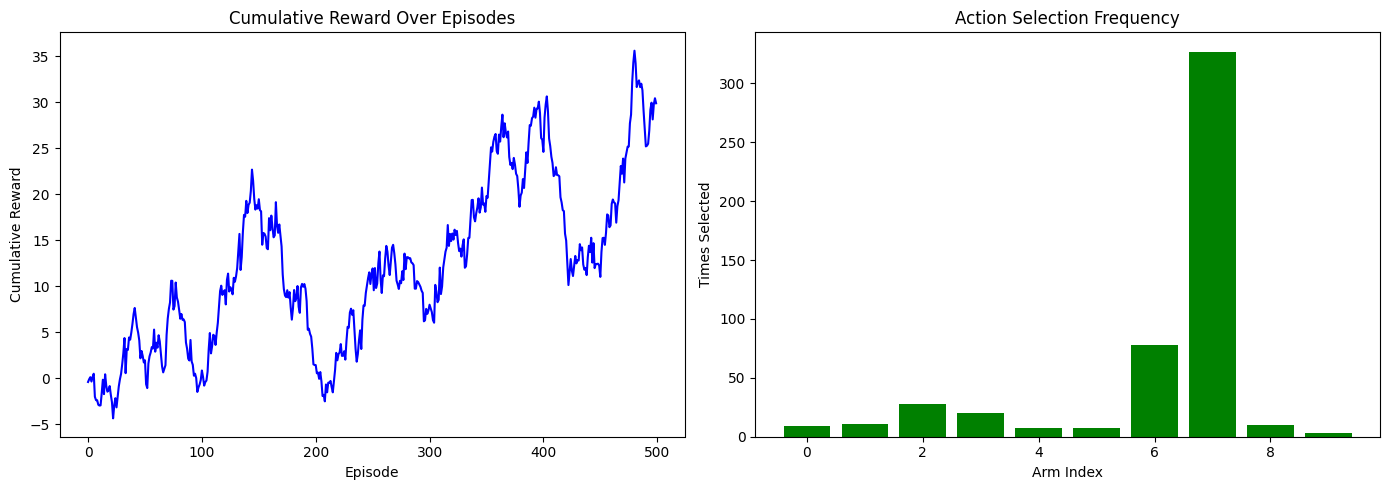

In [23]:
import matplotlib.pyplot as plt

plt. figure(figsize=(14, 5))

plt.subplot (1, 2, 1)
plt.plot(np.cumsum(all_rewards), color='blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot (1, 2, 2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title("Action Selection Frequency")
plt.xlabel("Arm Index")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()